In [ ]:
# TASK - 1. Install PyTorch.
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE" ## << these two lines are added because my kernel crashes without it.
!pip install torch torchvision matplotlib
import torch
import torch.nn as nn
import torch.nn.functional as F
## ^^ Imported fot Task 4.
import matplotlib.pyplot as plt
## ^^ Imported for Task 3.


print(torch.__version__)

2.14.0+cpu


In [14]:
# TASK - 2. Download and Load the Dataset.
import torchvision
import torchvision.transforms as transforms

transform = transforms.ToTensor()
## ^^ Normalizes image sizes.

train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
## ^^ prepares training set.
test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
## ^^ prepares test set.

train_loader = torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True)
## ^^ loads training set.
test_loader = torch.utils.data.DataLoader(test_set, batch_size=32, shuffle=False)
## ^^ loads test set.

print("Train images:", len(train_set))
print("Test images:", len(test_set))

Train images: 60000
Test images: 10000


Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])
Pixel range: 0.0 to 1.0


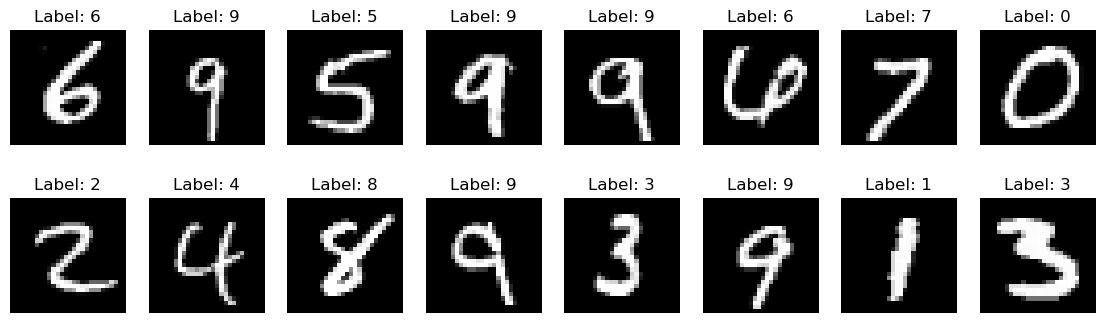

In [13]:
# TASK - 3. Inspect the Dataset.
images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis('off')
plt.show()

In [12]:
# TASK - 4. Creating A Simple Network.
class SimpleNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
                            #28x28 ^^
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        ## ^^ Layer 1
        self.fc2 = nn.Linear(hidden_size, num_classes)
        ## ^^ Layer 2

    def forward(self, x):
        x = torch.flatten(x, 1)   # (32, 1, 28, 28) -> (32, 784)
        x = F.relu(self.fc1(x))   # hidden layer + ReLU
        x = self.fc2(x)           # output layer (10 class scores)
        return x

net = SimpleNet()
print(net)

# Verify against the requirement
out = net(images)
print("Input shape:", images.shape)
print("Flattened shape:", torch.flatten(images, 1).shape)
print("Output shape:", out.shape)

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Input shape: torch.Size([32, 1, 28, 28])
Flattened shape: torch.Size([32, 784])
Output shape: torch.Size([32, 10])


In [ ]:
# TASK - 5. Training Function.
import torch.optim as optim

def train(net, train_loader, epochs=5, lr=0.01, momentum=0.9):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)
    ## ^^ Pre determined from Tasks description.
    
    all_losses = []
    epoch_losses = []
    epoch_accs = []

    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for i, (inputs, labels) in enumerate(train_loader):
            optimizer.zero_grad() #clears old gradients
            outputs = net(inputs) #calls forward function
            loss = criterion(outputs, labels) #computes the loss.
            loss.backward() #computes gradients.
            optimizer.step() #updates the weights.

            all_losses.append(loss.item())
            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            ## ^^^ picks the highest-scoring digit as the prediction, which is used for accuracy.
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            if (i + 1) % 200 == 0:
                print(f"Epoch {epoch+1}/{epochs}, Batch {i+1}, "
                      f"Loss: {loss.item():.4f}, Acc: {100*correct/total:.2f}%")
                ## ^^ Epoch Debug Info for TASK - 6.

        epoch_losses.append(running_loss / len(train_loader))
        epoch_accs.append(100 * correct / total)
        print(f"--- Epoch {epoch+1} done: Loss {epoch_losses[-1]:.4f}, Acc {epoch_accs[-1]:.2f}%")

    return all_losses, epoch_losses, epoch_accs

In [16]:
# TASK - 6. Training Network.

net = SimpleNet()
# ^^ create network from TASK - 4 class.

all_losses, epoch_losses, epoch_accs = train(net, train_loader, epochs=5, lr=0.01, momentum=0.9)
# ^^ Traininf the network and retrieving feedback from Train TASK - 5 function.

Epoch 1/5, Batch 200, Loss: 0.6463, Acc: 72.77%
Epoch 1/5, Batch 400, Loss: 0.2602, Acc: 80.73%
Epoch 1/5, Batch 600, Loss: 0.2158, Acc: 83.71%
Epoch 1/5, Batch 800, Loss: 0.3636, Acc: 85.59%
Epoch 1/5, Batch 1000, Loss: 0.3768, Acc: 86.86%
Epoch 1/5, Batch 1200, Loss: 0.2893, Acc: 87.79%
Epoch 1/5, Batch 1400, Loss: 0.1497, Acc: 88.61%
Epoch 1/5, Batch 1600, Loss: 0.4715, Acc: 89.25%
Epoch 1/5, Batch 1800, Loss: 0.2227, Acc: 89.74%
--- Epoch 1 done: Loss 0.3552, Acc 89.89%
Epoch 2/5, Batch 200, Loss: 0.4240, Acc: 94.66%
Epoch 2/5, Batch 400, Loss: 0.0514, Acc: 94.95%
Epoch 2/5, Batch 600, Loss: 0.1449, Acc: 94.92%
Epoch 2/5, Batch 800, Loss: 0.0346, Acc: 94.99%
Epoch 2/5, Batch 1000, Loss: 0.2555, Acc: 95.06%
Epoch 2/5, Batch 1200, Loss: 0.2398, Acc: 95.14%
Epoch 2/5, Batch 1400, Loss: 0.1399, Acc: 95.15%
Epoch 2/5, Batch 1600, Loss: 0.2021, Acc: 95.22%
Epoch 2/5, Batch 1800, Loss: 0.0473, Acc: 95.29%
--- Epoch 2 done: Loss 0.1598, Acc 95.32%
Epoch 3/5, Batch 200, Loss: 0.0732, Acc: 9

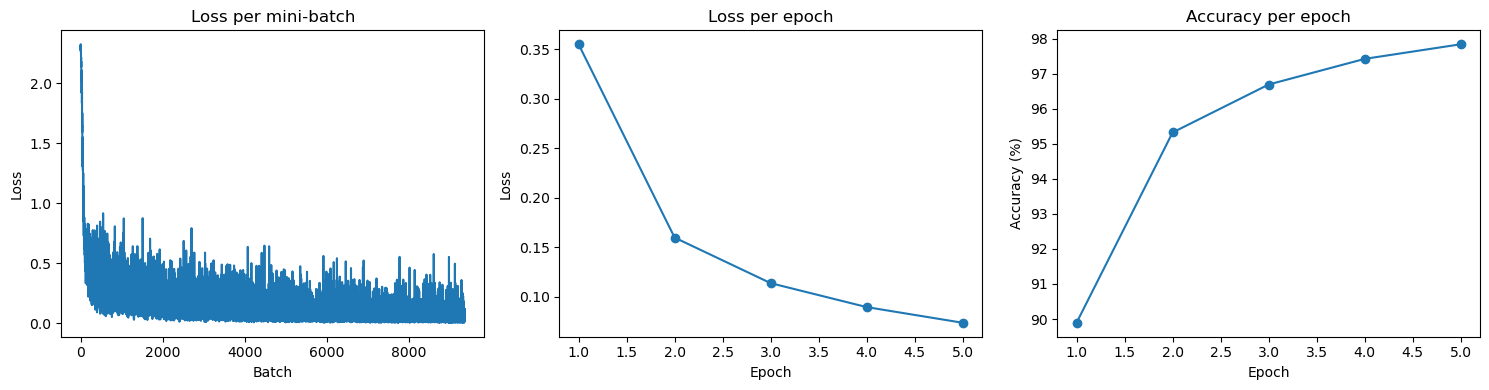

In [ ]:
# TASK - 6 . 1.
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(all_losses)
plt.title("Loss per mini-batch")
plt.xlabel("Batch")
plt.ylabel("Loss")

plt.subplot(1, 3, 2)
plt.plot(range(1, len(epoch_losses)+1), epoch_losses, marker='o')
plt.title("Loss per epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 3, 3)
plt.plot(range(1, len(epoch_accs)+1), epoch_accs, marker='o')
plt.title("Accuracy per epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

Test accuracy: 97.52% (9752/10000)


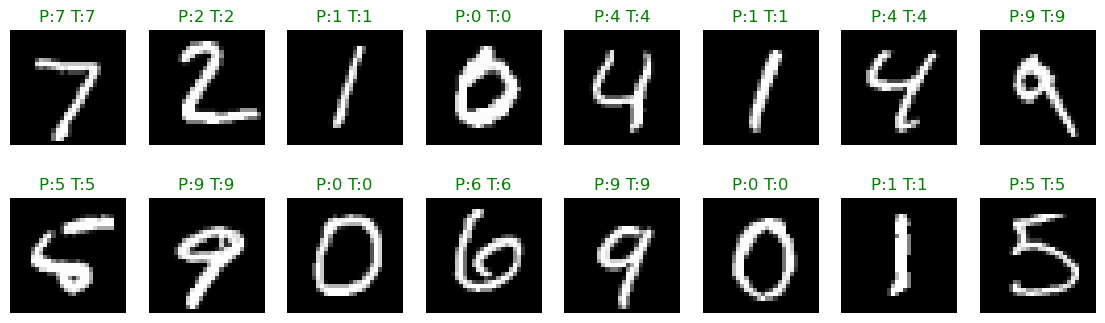

In [ ]:
# TASK - 7. Testing Network.

correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = net(inputs)
        _, predicted = torch.max(outputs, 1)
        #^^takes the highest score along dimension 1, the digit with the highest score per image.
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test accuracy: {100*correct/total:.2f}% ({correct}/{total})")

# Predictions on a few test images
images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = net(images)
    _, predicted = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    color = 'green' if predicted[i] == labels[i] else 'red'
    ax.set_title(f"P:{predicted[i].item()} T:{labels[i].item()}", color=color)
    ax.axis('off')
plt.show()

In [ ]:
import io, contextlib

def evaluate(net, loader):
    net.eval()
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in loader:
            _, predicted = torch.max(net(inputs), 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

results = []

for lr in [0.001, 0.01, 0.05, 0.1]:
    for momentum in [0.0, 0.5, 0.9]:
        #^^ Tests the combinations of 4 learning rates and 3 momentums

        torch.manual_seed(0) ## << fixes the random number generator to illiminate variance differences.
        net = SimpleNet()

        with contextlib.redirect_stdout(io.StringIO()): ## << causes the printed epoch output to go elsewhere (just to reduce clutter)
            _, ep_losses, ep_accs = train(net, train_loader, epochs=3, lr=lr, momentum=momentum)
            ## ^^ Trains for 3 epochs using current momentum and lr values.

        test_acc = evaluate(net, test_loader) ## applies evaluate to current instance

        results.append((lr, momentum, ep_losses[-1], test_acc)) 
        print(f"lr={lr:<6} momentum={momentum:<4} final loss={ep_losses[-1]:.4f}  test acc={test_acc:.2f}%")

best = max(results, key=lambda r: r[3])
print(f"\nBEST: lr={best[0]}, momentum={best[1]}, loss={best[2]:.4f}, test acc={best[3]:.2f}%")

lr=0.001  momentum=0.0  final loss=1.0348  test acc=82.99%
lr=0.001  momentum=0.5  final loss=0.6106  test acc=87.45%
lr=0.001  momentum=0.9  final loss=0.3227  test acc=91.68%
lr=0.01   momentum=0.0  final loss=0.3227  test acc=91.67%
lr=0.01   momentum=0.5  final loss=0.2626  test acc=93.17%
lr=0.01   momentum=0.9  final loss=0.1131  test acc=96.80%
lr=0.05   momentum=0.0  final loss=0.1701  test acc=95.56%
lr=0.05   momentum=0.5  final loss=0.1121  test acc=96.73%
lr=0.05   momentum=0.9  final loss=0.0771  test acc=96.82%
lr=0.1    momentum=0.0  final loss=0.1111  test acc=96.85%
lr=0.1    momentum=0.5  final loss=0.0804  test acc=97.15%
lr=0.1    momentum=0.9  final loss=0.1376  test acc=95.86%

BEST: lr=0.1, momentum=0.5, loss=0.0804, test acc=97.15%
